In [2]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn plotly joblib

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print("Imports successful.")

Imports successful.


In [4]:
def make_sample_transactions(n_customers=1200, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    today = pd.Timestamp.today().normalize()
    rows = []
    customer_ids = np.arange(10001, 10001 + n_customers)

    # Hidden patterns used only to create realistic demo data.
    patterns = rng.choice(
        ["loyal_high_value", "regular", "new_or_recent", "at_risk", "low_engagement"],
        size=n_customers,
        p=[0.14, 0.30, 0.16, 0.18, 0.22]
    )

    for cid, pattern in zip(customer_ids, patterns):
        if pattern == "loyal_high_value":
            n_tx = int(rng.integers(12, 31))
            age_days = rng.integers(0, 45, size=n_tx)
            basket = rng.lognormal(mean=4.0, sigma=0.45, size=n_tx)
        elif pattern == "regular":
            n_tx = int(rng.integers(6, 17))
            age_days = rng.integers(0, 180, size=n_tx)
            basket = rng.lognormal(mean=3.5, sigma=0.50, size=n_tx)
        elif pattern == "new_or_recent":
            n_tx = int(rng.integers(1, 5))
            age_days = rng.integers(0, 35, size=n_tx)
            basket = rng.lognormal(mean=3.4, sigma=0.55, size=n_tx)
        elif pattern == "at_risk":
            n_tx = int(rng.integers(5, 15))
            age_days = rng.integers(100, 366, size=n_tx)
            basket = rng.lognormal(mean=3.7, sigma=0.55, size=n_tx)
        else:
            n_tx = int(rng.integers(1, 7))
            age_days = rng.integers(30, 366, size=n_tx)
            basket = rng.lognormal(mean=2.9, sigma=0.60, size=n_tx)

        for age, amount in zip(age_days, basket):
            rows.append({
                "CustomerID": int(cid),
                "InvoiceDate": today - pd.Timedelta(days=int(age)),
                "Quantity": int(rng.integers(1, 5)),
                "UnitPrice": round(float(amount / rng.integers(1, 4)), 2)
            })

    tx = pd.DataFrame(rows)
    tx["InvoiceDate"] = pd.to_datetime(tx["InvoiceDate"])
    tx["Sales"] = tx["Quantity"] * tx["UnitPrice"]
    return tx

transactions = make_sample_transactions()

print(f"Transactions: {len(transactions):,}")
print(f"Unique customers: {transactions['CustomerID'].nunique():,}")
display(transactions.head())

Transactions: 11,062
Unique customers: 1,200


,CustomerID,InvoiceDate,Quantity,UnitPrice,Sales
0,10001,2026-02-11,3,108.96,326.88
1,10001,2025-12-25,2,16.13,32.26
2,10001,2026-02-15,2,11.04,22.08
3,10001,2026-03-31,1,7.17,7.17
4,10001,2025-12-03,2,7.08,14.16


In [5]:
# OPTIONAL CSV IMPORT — set to True to upload your own file in Google Colab.
USE_UPLOADED_CSV = False

if USE_UPLOADED_CSV:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No file was uploaded.")
    filename = next(iter(uploaded))
    imported = pd.read_csv(filename)

    required = {"CustomerID", "InvoiceDate", "Quantity", "UnitPrice"}
    missing = required - set(imported.columns)
    if missing:
        raise ValueError(f"CSV is missing required columns: {sorted(missing)}")

    imported["InvoiceDate"] = pd.to_datetime(imported["InvoiceDate"], errors="coerce")
    imported["Quantity"] = pd.to_numeric(imported["Quantity"], errors="coerce")
    imported["UnitPrice"] = pd.to_numeric(imported["UnitPrice"], errors="coerce")
    imported = imported.dropna(subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"])
    imported = imported[(imported["Quantity"] > 0) & (imported["UnitPrice"] >= 0)]

    if imported.empty:
        raise ValueError("No valid transactions remain after cleaning.")

    imported["Sales"] = imported["Quantity"] * imported["UnitPrice"]
    transactions = imported.copy()
    print(f"Loaded {len(transactions):,} valid transactions from {filename}.")
else:
    print("Using generated sample data. Set USE_UPLOADED_CSV = True to import a file.")

Using generated sample data. Set USE_UPLOADED_CSV = True to import a file.


Dataset shape: (11062, 5)

Missing values:


,Missing count
CustomerID,0
InvoiceDate,0
Quantity,0
UnitPrice,0
Sales,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Quantity,11062.0,2.508046,1.121527,1.00,2.0000,3.00,4.0000,4.00
UnitPrice,11062.0,27.978963,22.476859,1.19,12.7925,21.16,36.0375,213.46
Sales,11062.0,70.182160,69.340195,1.65,25.6900,47.83,89.6175,799.32


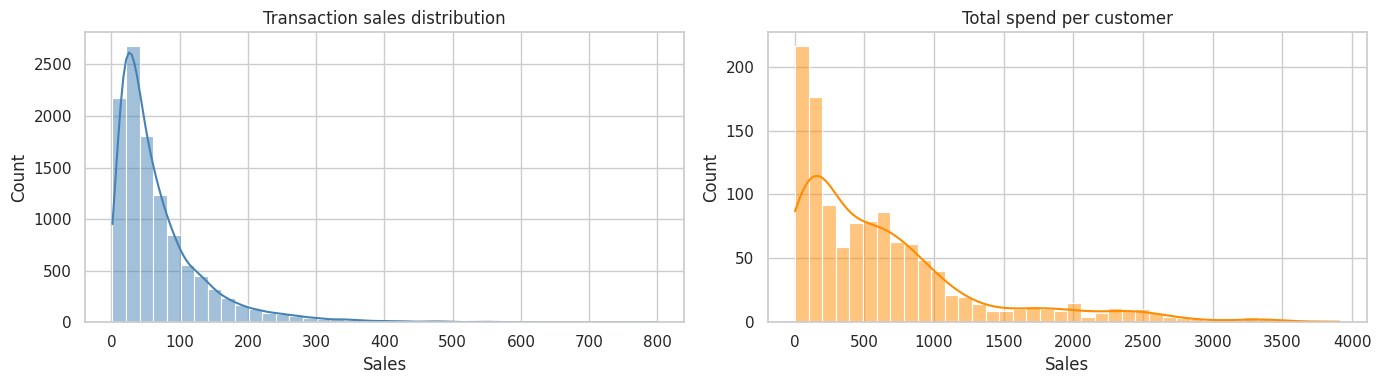

In [6]:
print("Dataset shape:", transactions.shape)
print("\nMissing values:")
display(transactions.isna().sum().to_frame("Missing count"))

print("\nDescriptive statistics:")
display(transactions[["Quantity", "UnitPrice", "Sales"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(transactions["Sales"], bins=40, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Transaction sales distribution")
sns.histplot(transactions.groupby("CustomerID")["Sales"].sum(), bins=40, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Total spend per customer")
plt.tight_layout()
plt.show()

In [7]:
reference_date = transactions["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = transactions.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceDate", "size"),
    Monetary=("Sales", "sum")
).reset_index()

rfm["Recency"] = (reference_date - rfm["LastPurchase"].dt.normalize()).dt.days
rfm = rfm[["CustomerID", "Recency", "Frequency", "Monetary"]].copy()
rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna()
rfm = rfm[(rfm["Recency"] >= 0) & (rfm["Frequency"] > 0) & (rfm["Monetary"] >= 0)]
rfm = rfm.reset_index(drop=True)

if len(rfm) < 10:
    raise ValueError("Need at least 10 valid customers for this clustering workflow.")

print("Customer-level RFM table:", rfm.shape)
display(rfm.head(10))
display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)

Customer-level RFM table: (1200, 4)


,CustomerID,Recency,Frequency,Monetary
0,10001,203,5,402.55
1,10002,24,7,479.52
2,10003,96,3,71.88
3,10004,136,5,541.61
4,10005,5,12,888.28
5,10006,141,6,201.59
6,10007,149,13,980.44
7,10008,56,2,25.34
8,10009,4,28,3280.91
9,10010,25,1,4.34


,count,mean,std,min,25%,50%,75%,max
Recency,1200.0,57.406667,69.157551,1.00,5.00,22.000,108.00,366.00
Frequency,1200.0,9.218333,6.806683,1.00,4.00,8.000,13.00,30.00
Monetary,1200.0,646.962542,680.652975,2.96,144.69,475.415,855.65,3909.32


,k,silhouette_score,davies_bouldin_score,inertia
0,2,0.422812,0.928094,1818.107905
1,4,0.422105,0.883211,873.358043
2,3,0.410204,0.865121,1154.745499
3,6,0.401459,0.826926,545.670979
4,7,0.389524,0.889357,482.543431
5,8,0.387173,0.933978,424.376880
6,5,0.385601,0.917519,705.646408


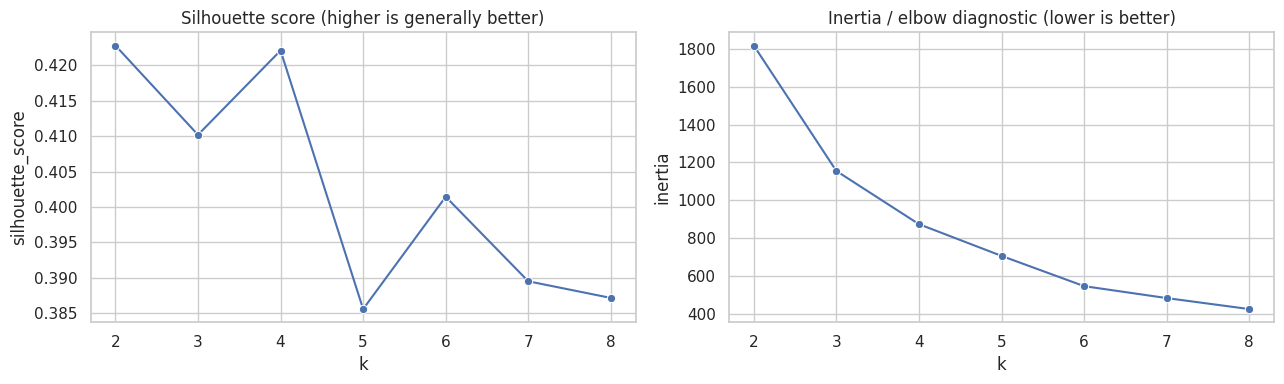

Selected number of clusters: 2


In [8]:
FEATURES = ["Recency", "Frequency", "Monetary"]

X_raw = rfm[FEATURES].astype(float).copy()
X_log = np.log1p(X_raw.clip(lower=0))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

max_k = min(8, len(rfm) - 1)
candidate_ks = list(range(2, max_k + 1))
evaluation_rows = []

for k in candidate_ks:
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = candidate.fit_predict(X_scaled)

    # Silhouette is undefined if the result has only one effective cluster
    # or every point is assigned to its own cluster.
    if 1 < len(np.unique(labels)) < len(rfm):
        sil = silhouette_score(X_scaled, labels)
        db = davies_bouldin_score(X_scaled, labels)
        evaluation_rows.append({
            "k": k,
            "silhouette_score": sil,
            "davies_bouldin_score": db,
            "inertia": candidate.inertia_
        })

evaluation = pd.DataFrame(evaluation_rows)
if evaluation.empty:
    raise RuntimeError("Could not evaluate candidate cluster counts.")

display(evaluation.sort_values("silhouette_score", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=evaluation, x="k", y="silhouette_score", marker="o", ax=ax[0])
ax[0].set_title("Silhouette score (higher is generally better)")
sns.lineplot(data=evaluation, x="k", y="inertia", marker="o", ax=ax[1])
ax[1].set_title("Inertia / elbow diagnostic (lower is better)")
plt.tight_layout()
plt.show()

BEST_K = int(evaluation.loc[evaluation["silhouette_score"].idxmax(), "k"])
print("Selected number of clusters:", BEST_K)

In [9]:
kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=20)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

final_silhouette = silhouette_score(X_scaled, rfm["Cluster"])
final_db = davies_bouldin_score(X_scaled, rfm["Cluster"])

print(f"Final silhouette score: {final_silhouette:.4f}")
print(f"Final Davies–Bouldin score: {final_db:.4f}")
print("\nCustomers per cluster:")
display(rfm["Cluster"].value_counts().sort_index().rename("Customers").to_frame())

Final silhouette score: 0.4228
Final Davies–Bouldin score: 0.9281

Customers per cluster:


,Customers
Cluster,
0,677
1,523


In [10]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    MedianRecency=("Recency", "median"),
    AvgFrequency=("Frequency", "mean"),
    MedianFrequency=("Frequency", "median"),
    AvgMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median")
).round(2)

overall_r = rfm["Recency"].median()
overall_f = rfm["Frequency"].median()
overall_m = rfm["Monetary"].median()

def name_segment(row):
    recent = row["MedianRecency"] <= overall_r
    frequent = row["MedianFrequency"] >= overall_f
    high_value = row["MedianMonetary"] >= overall_m

    if recent and frequent and high_value:
        return "Champions / High Value"
    if (not recent) and frequent and high_value:
        return "At-Risk High Value"
    if recent and not frequent:
        return "Recent / New Customers"
    if frequent:
        return "Regular Customers"
    if not recent and not high_value:
        return "Dormant / Low Engagement"
    return "Occasional Customers"

cluster_profile["Segment"] = cluster_profile.apply(name_segment, axis=1)

# If heuristic conditions assign the same name to multiple clusters, append
# a cluster identifier so each group remains distinguishable in charts.
dupe_names = cluster_profile["Segment"].duplicated(keep=False)
cluster_profile.loc[dupe_names, "Segment"] = (
    cluster_profile.loc[dupe_names, "Segment"]
    + " (Cluster "
    + cluster_profile.loc[dupe_names].index.astype(str)
    + ")"
)

segment_map = cluster_profile["Segment"].to_dict()
rfm["Segment"] = rfm["Cluster"].map(segment_map)

display(cluster_profile.sort_values("Customers", ascending=False))

,Customers,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,Segment
Cluster,,,,,,,,
0,677,38.21,10.0,13.71,13.0,1032.60,796.64,Champions / High Value
1,523,82.26,57.0,3.40,3.0,147.77,125.88,Dormant / Low Engagement


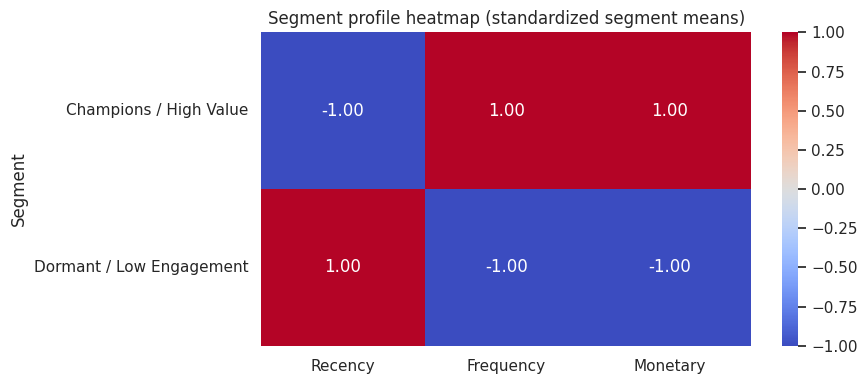

In [11]:
# Plot 1: customer counts by segment
segment_counts = rfm["Segment"].value_counts().rename_axis("Segment").reset_index(name="Customers")
fig = px.bar(
    segment_counts, x="Segment", y="Customers", color="Segment",
    title="Customer count by segment", text="Customers"
)
fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="Customers")
fig.show()

# Plot 2: Recency vs Monetary, with logarithmic display for spending
fig = px.scatter(
    rfm, x="Recency", y="Monetary", color="Segment",
    hover_data=["CustomerID", "Frequency", "Cluster"],
    title="Customer segments: Recency vs Monetary value",
    log_y=True
)
fig.update_layout(xaxis_title="Recency (days; lower means more recent)",
                  yaxis_title="Monetary value (log scale)")
fig.show()

# Plot 3: Frequency vs Monetary
fig = px.scatter(
    rfm, x="Frequency", y="Monetary", color="Segment",
    hover_data=["CustomerID", "Recency", "Cluster"],
    title="Customer segments: Frequency vs Monetary value",
    log_y=True
)
fig.show()

# Plot 4: cluster profile heatmap on normalized mean RFM values
heatmap_data = rfm.groupby("Segment")[FEATURES].mean()
heatmap_scaled = (heatmap_data - heatmap_data.mean()) / heatmap_data.std(ddof=0).replace(0, 1)

plt.figure(figsize=(9, max(4, len(heatmap_scaled) * 0.7)))
sns.heatmap(heatmap_scaled, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Segment profile heatmap (standardized segment means)")
plt.tight_layout()
plt.show()

# Plot 5: PCA projection of the scaled feature space (2D visualization only)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "Segment": rfm["Segment"].values,
    "CustomerID": rfm["CustomerID"].values
})
fig = px.scatter(
    pca_df, x="PC1", y="PC2", color="Segment",
    hover_data=["CustomerID"], title="Customer clusters projected into 2D with PCA"
)
fig.update_layout(
    xaxis_title=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
    yaxis_title=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)"
)
fig.show()

In [12]:
total_customers = len(rfm)
total_revenue = float(rfm["Monetary"].sum())
avg_revenue = float(rfm["Monetary"].mean())
top_segment = cluster_profile["Customers"].idxmax()
top_segment_name = cluster_profile.loc[top_segment, "Segment"]

print("=" * 60)
print("CUSTOMER SEGMENTATION BUSINESS SUMMARY")
print("=" * 60)
print(f"Customers analyzed: {total_customers:,}")
print(f"Total recorded sales: {total_revenue:,.2f}")
print(f"Average customer monetary value: {avg_revenue:,.2f}")
print(f"Largest segment: {top_segment_name}")
print(f"Selected clusters: {BEST_K}")
print(f"Silhouette score: {final_silhouette:.3f}")

print("\nSuggested actions (review the profiles before applying):")
for _, row in cluster_profile.iterrows():
    name = row["Segment"]
    recency = row["AvgRecency"]
    frequency = row["AvgFrequency"]
    monetary = row["AvgMonetary"]

    if "Champions" in name:
        action = "Reward loyalty; test VIP benefits and retention offers."
    elif "At-Risk" in name:
        action = "Consider a carefully targeted win-back campaign."
    elif "New" in name or "Recent" in name:
        action = "Improve onboarding and encourage a second purchase."
    elif "Dormant" in name:
        action = "Test low-cost re-engagement before investing heavily."
    elif "Regular" in name:
        action = "Test cross-sell or loyalty incentives."
    else:
        action = "Test relevant offers and monitor repeat purchases."

    print(f"- {name}: {action} "
          f"(avg recency={recency:.1f} days, "
          f"avg frequency={frequency:.1f}, avg monetary={monetary:,.2f})")

CUSTOMER SEGMENTATION BUSINESS SUMMARY
Customers analyzed: 1,200
Total recorded sales: 776,355.05
Average customer monetary value: 646.96
Largest segment: Champions / High Value
Selected clusters: 2
Silhouette score: 0.423

Suggested actions (review the profiles before applying):
- Champions / High Value: Reward loyalty; test VIP benefits and retention offers. (avg recency=38.2 days, avg frequency=13.7, avg monetary=1,032.60)
- Dormant / Low Engagement: Test low-cost re-engagement before investing heavily. (avg recency=82.3 days, avg frequency=3.4, avg monetary=147.77)


In [13]:
OUTPUT_DIR = "/content/customer_segmentation_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

rfm_path = os.path.join(OUTPUT_DIR, "customer_segments.csv")
profile_path = os.path.join(OUTPUT_DIR, "segment_profiles.csv")
evaluation_path = os.path.join(OUTPUT_DIR, "cluster_evaluation.csv")
transaction_path = os.path.join(OUTPUT_DIR, "transactions_used.csv")
model_path = os.path.join(OUTPUT_DIR, "customer_segmentation_model.joblib")
metadata_path = os.path.join(OUTPUT_DIR, "model_metadata.json")

rfm.to_csv(rfm_path, index=False)
cluster_profile.to_csv(profile_path)
evaluation.to_csv(evaluation_path, index=False)
transactions.to_csv(transaction_path, index=False)

joblib.dump({
    "scaler": scaler,
    "kmeans": kmeans,
    "features": FEATURES,
    "best_k": BEST_K,
    "segment_map": segment_map
}, model_path)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump({
        "project": "Customer Segmentation & Analytics",
        "algorithm": "KMeans",
        "features": FEATURES,
        "best_k": BEST_K,
        "silhouette_score": float(final_silhouette),
        "davies_bouldin_score": float(final_db),
        "data_type": "synthetic sample data" if not USE_UPLOADED_CSV else "user-uploaded CSV"
    }, f, indent=2)

print("Saved files:")
for name in os.listdir(OUTPUT_DIR):
    print("-", os.path.join(OUTPUT_DIR, name))

Saved files:
- /content/customer_segmentation_outputs/customer_segmentation_model.joblib
- /content/customer_segmentation_outputs/transactions_used.csv
- /content/customer_segmentation_outputs/segment_profiles.csv
- /content/customer_segmentation_outputs/model_metadata.json
- /content/customer_segmentation_outputs/customer_segments.csv
- /content/customer_segmentation_outputs/cluster_evaluation.csv


In [14]:
# Data integrity tests
assert not rfm.empty, "RFM table must not be empty."
assert rfm["CustomerID"].is_unique, "RFM should have one row per customer."
assert rfm[FEATURES].notna().all().all(), "RFM features must not contain missing values."
assert (rfm["Recency"] >= 0).all(), "Recency cannot be negative."
assert (rfm["Frequency"] > 0).all(), "Frequency must be positive."
assert (rfm["Monetary"] >= 0).all(), "Monetary value cannot be negative."
assert rfm["Cluster"].nunique() == BEST_K, "Expected all selected clusters to be represented."
assert rfm["Segment"].notna().all(), "Every customer must have a segment label."

# Prediction-path test using the fitted preprocessing and model.
example = rfm.loc[0, FEATURES].to_frame().T.astype(float)
example_transformed = scaler.transform(np.log1p(example.clip(lower=0)))
predicted_cluster = int(kmeans.predict(example_transformed)[0])
assert predicted_cluster in set(rfm["Cluster"]), "Prediction must map to a known cluster."

# Save/load test
loaded = joblib.load(model_path)
loaded_cluster = int(
    loaded["kmeans"].predict(
        loaded["scaler"].transform(np.log1p(example.clip(lower=0)))
    )[0]
)
assert loaded_cluster == predicted_cluster, "Saved model prediction mismatch."

print("All sanity checks passed.")
print("Example customer:", int(rfm.loc[0, "CustomerID"]))
print("Assigned cluster:", predicted_cluster)
print("Assigned segment:", segment_map[predicted_cluster])

All sanity checks passed.
Example customer: 10001
Assigned cluster: 1
Assigned segment: Dormant / Low Engagement


In [15]:
import shutil
from google.colab import files

zip_path = shutil.make_archive("/content/customer_segmentation_outputs", "zip", OUTPUT_DIR)
print("Created:", zip_path)
files.download(zip_path)

Created: /content/customer_segmentation_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>